# Air Quality Analysis and Decision-Support System

Analysis of daily AQI for **Delhi, Mumbai and Bengaluru** from CPCB daily AQI bulletins.

**Data source.** *Air Quality Index for Indian Cities 2015-2023* (Guttikunda, S.; data curators Dammalapati, S. K.,
Patel, Z. B., Batra, N., IIT Gandhinagar), Zenodo, DOI [10.5281/zenodo.11146316](https://doi.org/10.5281/zenodo.11146316),
licence CC BY 4.0. The file contains city-average AQI values parsed from the CPCB daily AQI bulletin PDFs by
UrbanEmissions.info. The copy used here is checked against the MD5 published on the Zenodo record.

**How the notebook is organised.** Each section is tagged so that empirical results, model/projection outputs and
scenario assumptions are never mixed:

| Tag | Meaning |
|---|---|
| **EMPIRICAL** | Computed directly from observed bulletin AQI (and observed IMD weather where stated) |
| **PROJECTION / HEURISTIC** | Simple linear trend and a project-defined score; not validated predictive models |
| **SCENARIO** | Based on assumptions stated in the section; not measurements or predictions |

## 1. Setup

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Works whether Jupyter is started in notebooks/ or in the repository root
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROCESSED, VISUALS = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed', ROOT / 'visuals'
PROCESSED.mkdir(parents=True, exist_ok=True)
VISUALS.mkdir(parents=True, exist_ok=True)

AQI_FILE = RAW / 'India_AQI_Bulletins_Master.csv'
ZENODO_MD5 = '7a3173948315bdf8ac97701f9fab5d06'   # md5 listed on the Zenodo record for India_AQI_Bulletins_Master.csv

CITIES = ['Delhi', 'Mumbai', 'Bengaluru']
COLORS = {'Delhi': '#d73027', 'Mumbai': '#4575b4', 'Bengaluru': '#1a9850'}
CAT_ORDER = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
CAT_BINS = [-np.inf, 50, 100, 200, 300, 400, np.inf]   # CPCB AQI category upper bounds
SEASON = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Pre-monsoon', 4: 'Pre-monsoon', 5: 'Pre-monsoon',
          6: 'Monsoon', 7: 'Monsoon', 8: 'Monsoon', 9: 'Monsoon', 10: 'Post-monsoon', 11: 'Post-monsoon'}
SEASON_ORDER = ['Winter', 'Pre-monsoon', 'Monsoon', 'Post-monsoon']
MIN_DAYS_FULL_YEAR = 300   # a year counts as "well covered" with at least this many observed days

plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white', 'axes.grid': True, 'grid.alpha': 0.3})

md5 = hashlib.md5(AQI_FILE.read_bytes()).hexdigest()
print('AQI file md5      :', md5)
print('Zenodo record md5 :', ZENODO_MD5)
print('Checksum match    :', md5 == ZENODO_MD5)

AQI file md5      : 7a3173948315bdf8ac97701f9fab5d06
Zenodo record md5 : 7a3173948315bdf8ac97701f9fab5d06
Checksum match    : True


## 2. Load Data (AQI)

Only the selected cities are kept. City names are used exactly as they appear in the source (the source already uses
"Bengaluru"; "Navi Mumbai" is a separate city in the bulletins and is not merged into Mumbai). No rows are added,
and no missing values are filled.

In [2]:
raw = pd.read_csv(AQI_FILE, low_memory=False)
print('All cities, all rows:', raw.shape, '| cities in file:', raw['City'].nunique())
print('Columns:', raw.columns.tolist())
print('City names containing "bang":', sorted(c for c in raw['City'].unique() if 'bang' in c.lower()))

aqi = raw.rename(columns={'City': 'city', 'No. Stations': 'stations_raw', 'Air Quality': 'category_reported',
                          'Index Value': 'aqi', 'Prominent Pollutant': 'prominent_pollutant'})
aqi['date'] = pd.to_datetime(aqi['date'], format='%Y-%m-%d')
aqi = aqi[aqi['city'].isin(CITIES)].copy()

# Light standardisation only: label capitalisation, and the station count (some source cells contain stray text such as '3(two')
aqi['category_reported'] = aqi['category_reported'].str.strip().replace({'Very poor': 'Very Poor'})
aqi['stations'] = pd.to_numeric(aqi['stations_raw'].astype('string').str.extract(r'^\s*(\d+)')[0], errors='coerce')
aqi = aqi.drop(columns='stations_raw').sort_values(['city', 'date']).reset_index(drop=True)

# AQI category derived from the AQI value with CPCB bounds (used in all analyses below)
aqi['aqi_category'] = pd.cut(aqi['aqi'], bins=CAT_BINS, labels=CAT_ORDER).astype(str)
aqi['year'] = aqi['date'].dt.year
aqi['month'] = aqi['date'].dt.month
aqi['season'] = aqi['month'].map(SEASON)

print('Selected cities:', aqi.shape)
mismatch = (aqi['aqi_category'] != aqi['category_reported'])
print(f'Rows where reported category differs from the category implied by the AQI value: {mismatch.sum()} of {len(aqi)} '
      '(reported labels kept in `category_reported`; analysis uses the AQI value)')

All cities, all rows: (299974, 6) | cities in file: 277
Columns: ['date', 'City', 'No. Stations', 'Air Quality', 'Index Value', 'Prominent Pollutant']
City names containing "bang": []
Selected cities: (9147, 10)
Rows where reported category differs from the category implied by the AQI value: 12 of 9147 (reported labels kept in `category_reported`; analysis uses the AQI value)


## 3. Data Quality (EMPIRICAL)

Real bulletin data is not complete. Gaps are reported, not repaired.

In [3]:
span = aqi.groupby('city')['date'].agg(['min', 'max'])
quality = pd.DataFrame({
    'observations': aqi.groupby('city').size(),
    'first_date': span['min'].dt.date,
    'last_date': span['max'].dt.date,
    'days_in_span': (span['max'] - span['min']).dt.days + 1,
    'duplicate_city_dates': aqi.groupby('city').apply(lambda g: g['date'].duplicated().sum(), include_groups=False),
    'missing_aqi_values': aqi.groupby('city')['aqi'].apply(lambda s: s.isna().sum()),
}).reindex(CITIES)
quality['missing_dates_in_span'] = quality['days_in_span'] - quality['observations']
quality['coverage_%'] = (100 * quality['observations'] / quality['days_in_span']).round(1)
print('Observations:', len(aqi), '| date range:', aqi['date'].min().date(), 'to', aqi['date'].max().date())
print('Fully duplicated rows:', int(aqi.duplicated().sum()))
print()
print(quality.to_string())
print()
print('Missing values by column (selected cities):')
print(aqi[['date', 'city', 'aqi', 'category_reported', 'stations', 'prominent_pollutant']].isna().sum().to_string())

Observations: 9147 | date range: 2015-05-01 to 2023-12-31
Fully duplicated rows: 0

           observations  first_date   last_date  days_in_span  duplicate_city_dates  missing_aqi_values  missing_dates_in_span  coverage_%
city                                                                                                                                      
Delhi              3143  2015-05-01  2023-12-31          3167                     0                   0                     24        99.2
Mumbai             2884  2015-08-20  2023-12-31          3056                     0                   0                    172        94.4
Bengaluru          3120  2015-05-02  2023-12-31          3166                     0                   0                     46        98.5

Missing values by column (selected cities):
date                    0
city                    0
aqi                     0
category_reported       0
stations               25
prominent_pollutant     0


In [4]:
availability = aqi.pivot_table(index='year', columns='city', values='aqi', aggfunc='count').reindex(columns=CITIES).fillna(0).astype(int)
print('Observed days per city and year (a full year has 365/366):')
print(availability.to_string())
print()
stations = aqi.pivot_table(index='year', columns='city', values='stations', aggfunc='median').reindex(columns=CITIES)
print('Median number of reporting stations per city and year (where reported):')
print(stations.round(1).to_string())

complete_years = {c: availability.index[availability[c] >= MIN_DAYS_FULL_YEAR].tolist() for c in CITIES}
print()
print(f'Years with >= {MIN_DAYS_FULL_YEAR} observed days (used for yearly means and the trend projection):')
for c in CITIES:
    print(f'  {c}: {complete_years[c]}')

Observed days per city and year (a full year has 365/366):
city  Delhi  Mumbai  Bengaluru
year                          
2015    235     118        227
2016    354     314        344
2017    363     347        358
2018    365     283        365
2019    365     362        365
2020    366     366        366
2021    365     365        365
2022    365     365        365
2023    365     364        365

Median number of reporting stations per city and year (where reported):
city  Delhi  Mumbai  Bengaluru
year                          
2015    5.0     1.0        3.0
2016    5.0     1.0        3.0
2017    9.0     1.0        4.0
2018   28.0     1.0        5.0
2019   34.0     7.0        8.0
2020   33.0     9.0        9.0
2021   35.0    18.0        8.0
2022   35.0    16.0        8.0
2023   36.0    19.0       11.0

Years with >= 300 observed days (used for yearly means and the trend projection):
  Delhi: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
  Mumbai: [2016, 2017, 2019, 2020, 2021, 2022

Notes on coverage: the bulletins start in 2015 (April/May), so 2015 is partial for every city, and Mumbai has
substantial gaps in 2015, 2016 and 2018. Percentages and yearly means below are computed over *observed* days only.
The number of reporting stations changes over time, and city-average AQI from few stations is less representative
of the whole city.

## 4. Weather Data: Identification and Matching (EMPIRICAL)

The two weather files have no city column. Their city is established from provenance, not guessed:

| Local file | Original download (resource id in the project's first notebook) | OpenCity resource title for that id |
|---|---|---|
| `weather_bengaluru.csv` (was `weather_1.csv`) | `.../resource/9cf80863-97ea-4ad8-a4ef-6a5f026debbb/download/ae01b010-...csv` | Bengaluru Daily Temperature Data 1951 to 2024 |
| `weather_delhi.csv` (was `weather_2.csv`) | `.../resource/0c853240-47a3-428c-bb5e-933e74245e08/download/82da1ebe-...csv` | Delhi Daily Temperature Data 1951 to 2024 |

The OpenCity dataset ("Daily Temperature - 70 years Data for Major Indian Cities", source listed as imd.gov.in, public
domain) lists the same URLs for these resources. The original notebook saved the first URL as `weather_1.csv` and the
second as `weather_2.csv`. The files were re-saved by pandas, so a byte-level hash comparison is not possible; a
climatology check is shown below as corroboration. There is **no Mumbai weather file**, so Mumbai is excluded from
all weather analysis. According to OpenCity, the series are gridded IMD data up to 2020 and station data
(via Ogimet) from 2021, so a level shift at 2021 is possible.

In [5]:
def load_weather(path, city):
    w = pd.read_csv(path, dtype=str)
    w['date'] = pd.to_datetime(w['Date'], format='%d-%m-%Y', errors='coerce')
    bad_dates = int(w['date'].isna().sum())
    w = w.dropna(subset=['date']).copy()
    rain_trace = int((w['Rain'] == 'Tr').sum())
    w['rain_mm'] = pd.to_numeric(w['Rain'].replace({'Tr': '0'}), errors='coerce')   # 'Tr' = trace rainfall, treated as 0
    w['temp_max'] = pd.to_numeric(w['Temp Max'], errors='coerce')                   # placeholders such as '-----' become missing
    w['temp_min'] = pd.to_numeric(w['Temp Min'], errors='coerce')
    print(f'{city}: {len(w)} rows ({w.date.min().date()} to {w.date.max().date()}); rows with unparseable date dropped: {bad_dates}; '
          f"trace-rain entries: {rain_trace}; missing temp_max: {int(w.temp_max.isna().sum())}, temp_min: {int(w.temp_min.isna().sum())}, rain: {int(w.rain_mm.isna().sum())}")
    return w[['date', 'temp_max', 'temp_min', 'rain_mm']].assign(city=city)


weather = pd.concat([load_weather(RAW / 'weather_bengaluru.csv', 'Bengaluru'),
                     load_weather(RAW / 'weather_delhi.csv', 'Delhi')], ignore_index=True)
print('Duplicate city-date rows in weather:', int(weather.duplicated(['city', 'date']).sum()))

# Climatology check: monthly mean of daily max temperature over the AQI period
period = weather[(weather['date'] >= aqi['date'].min()) & (weather['date'] <= aqi['date'].max())]
clim = period.pivot_table(index=period['date'].dt.month, columns='city', values='temp_max', aggfunc='mean').round(1)
print()
print('Mean daily max temperature by month, AQI period (consistent with Delhi: cold Jan, hot May; Bengaluru: milder, peak in April):')
print(clim.T.to_string())

Bengaluru: 26835 rows (1951-01-01 to 2024-06-20); rows with unparseable date dropped: 0; trace-rain entries: 127; missing temp_max: 7, temp_min: 10, rain: 8


Delhi: 26803 rows (1951-01-01 to 2024-06-19); rows with unparseable date dropped: 3; trace-rain entries: 49; missing temp_max: 54, temp_min: 55, rain: 54
Duplicate city-date rows in weather: 0

Mean daily max temperature by month, AQI period (consistent with Delhi: cold Jan, hot May; Bengaluru: milder, peak in April):
date         1     2     3     4     5     6     7     8     9     10    11    12
city                                                                             
Bengaluru  28.6  31.4  34.0  35.4  33.5  30.4  29.0  29.0  29.1  29.3  27.9  27.5
Delhi      19.9  25.6  31.1  37.7  39.6  39.0  35.2  34.4  34.6  33.5  28.2  22.5


In [6]:
# Merge on city + date; AQI days without a weather value are kept (weather columns stay missing)
aqi = aqi.merge(weather, on=['city', 'date'], how='left')

match = pd.DataFrame({
    'aqi_days': aqi.groupby('city').size(),
    'matched_to_weather_row': aqi.groupby('city')['temp_max'].apply(lambda s: s.notna().sum()),
}).reindex(CITIES)
for v in ['temp_max', 'temp_min', 'rain_mm']:
    match[f'valid_{v}'] = aqi.groupby('city')[v].apply(lambda s: s.notna().sum()).reindex(CITIES)
match['aqi_days_without_valid_temp_max_%'] = (100 - 100 * match['matched_to_weather_row'] / match['aqi_days']).round(1)
print('Overlap between AQI days and weather values (Mumbai: no weather file, not matched):')
print(match.to_string())

Overlap between AQI days and weather values (Mumbai: no weather file, not matched):
           aqi_days  matched_to_weather_row  valid_temp_max  valid_temp_min  valid_rain_mm  aqi_days_without_valid_temp_max_%
city                                                                                                                         
Delhi          3143                    3113            3113            3112           3113                                1.0
Mumbai         2884                       0               0               0              0                              100.0
Bengaluru      3120                    3117            3117            3115           3117                                0.1


## 5. Processed Dataset

Cleaned AQI observations for the three cities, with the matched weather columns (blank where unavailable), are saved
to `data/processed/aqi_daily_3cities.csv`.

In [7]:
out_cols = ['date', 'city', 'aqi', 'aqi_category', 'category_reported', 'stations', 'prominent_pollutant',
            'temp_max', 'temp_min', 'rain_mm', 'year', 'month', 'season']
aqi[out_cols].to_csv(PROCESSED / 'aqi_daily_3cities.csv', index=False)
print('Saved', (PROCESSED / 'aqi_daily_3cities.csv').relative_to(ROOT), aqi[out_cols].shape)

Saved data/processed/aqi_daily_3cities.csv (9147, 13)


## 6. AQI Distribution (EMPIRICAL)

In [8]:
desc = aqi.groupby('city')['aqi'].describe(percentiles=[0.5, 0.95]).reindex(CITIES).round(1)
print(desc.to_string())
print()
cat_share = (aqi.groupby('city')['aqi_category'].value_counts(normalize=True).mul(100).unstack(fill_value=0)
             .reindex(index=CITIES, columns=CAT_ORDER).round(1))
print('Share of observed days in each CPCB AQI category (%):')
print(cat_share.to_string())

            count   mean    std   min    50%    95%    max
city                                                      
Delhi      3143.0  217.1  104.0  41.0  209.0  399.0  497.0
Mumbai     2884.0  108.2   56.2  23.0   91.0  214.0  500.0
Bengaluru  3120.0   75.4   30.5  19.0   69.0  132.0  266.0

Share of observed days in each CPCB AQI category (%):
aqi_category  Good  Satisfactory  Moderate  Poor  Very Poor  Severe
city                                                               
Delhi          0.4          15.8      31.3  28.2       19.6     4.6
Mumbai        11.9          43.7      36.7   7.7        0.0     0.0
Bengaluru     20.5          61.3      17.7   0.5        0.0     0.0


## 7. AQI Trend Analysis (EMPIRICAL)

Monthly means use months with at least 15 observed days; yearly means use years with at least 300 observed days
(see Section 3), so incomplete periods do not distort the trend lines.

Caution: the number of stations behind each city average changed substantially over the period (Section 3: e.g. Delhi 5 -> 36,
Mumbai 1 -> 19), so part of any change over time may reflect the monitoring network rather than the air itself.

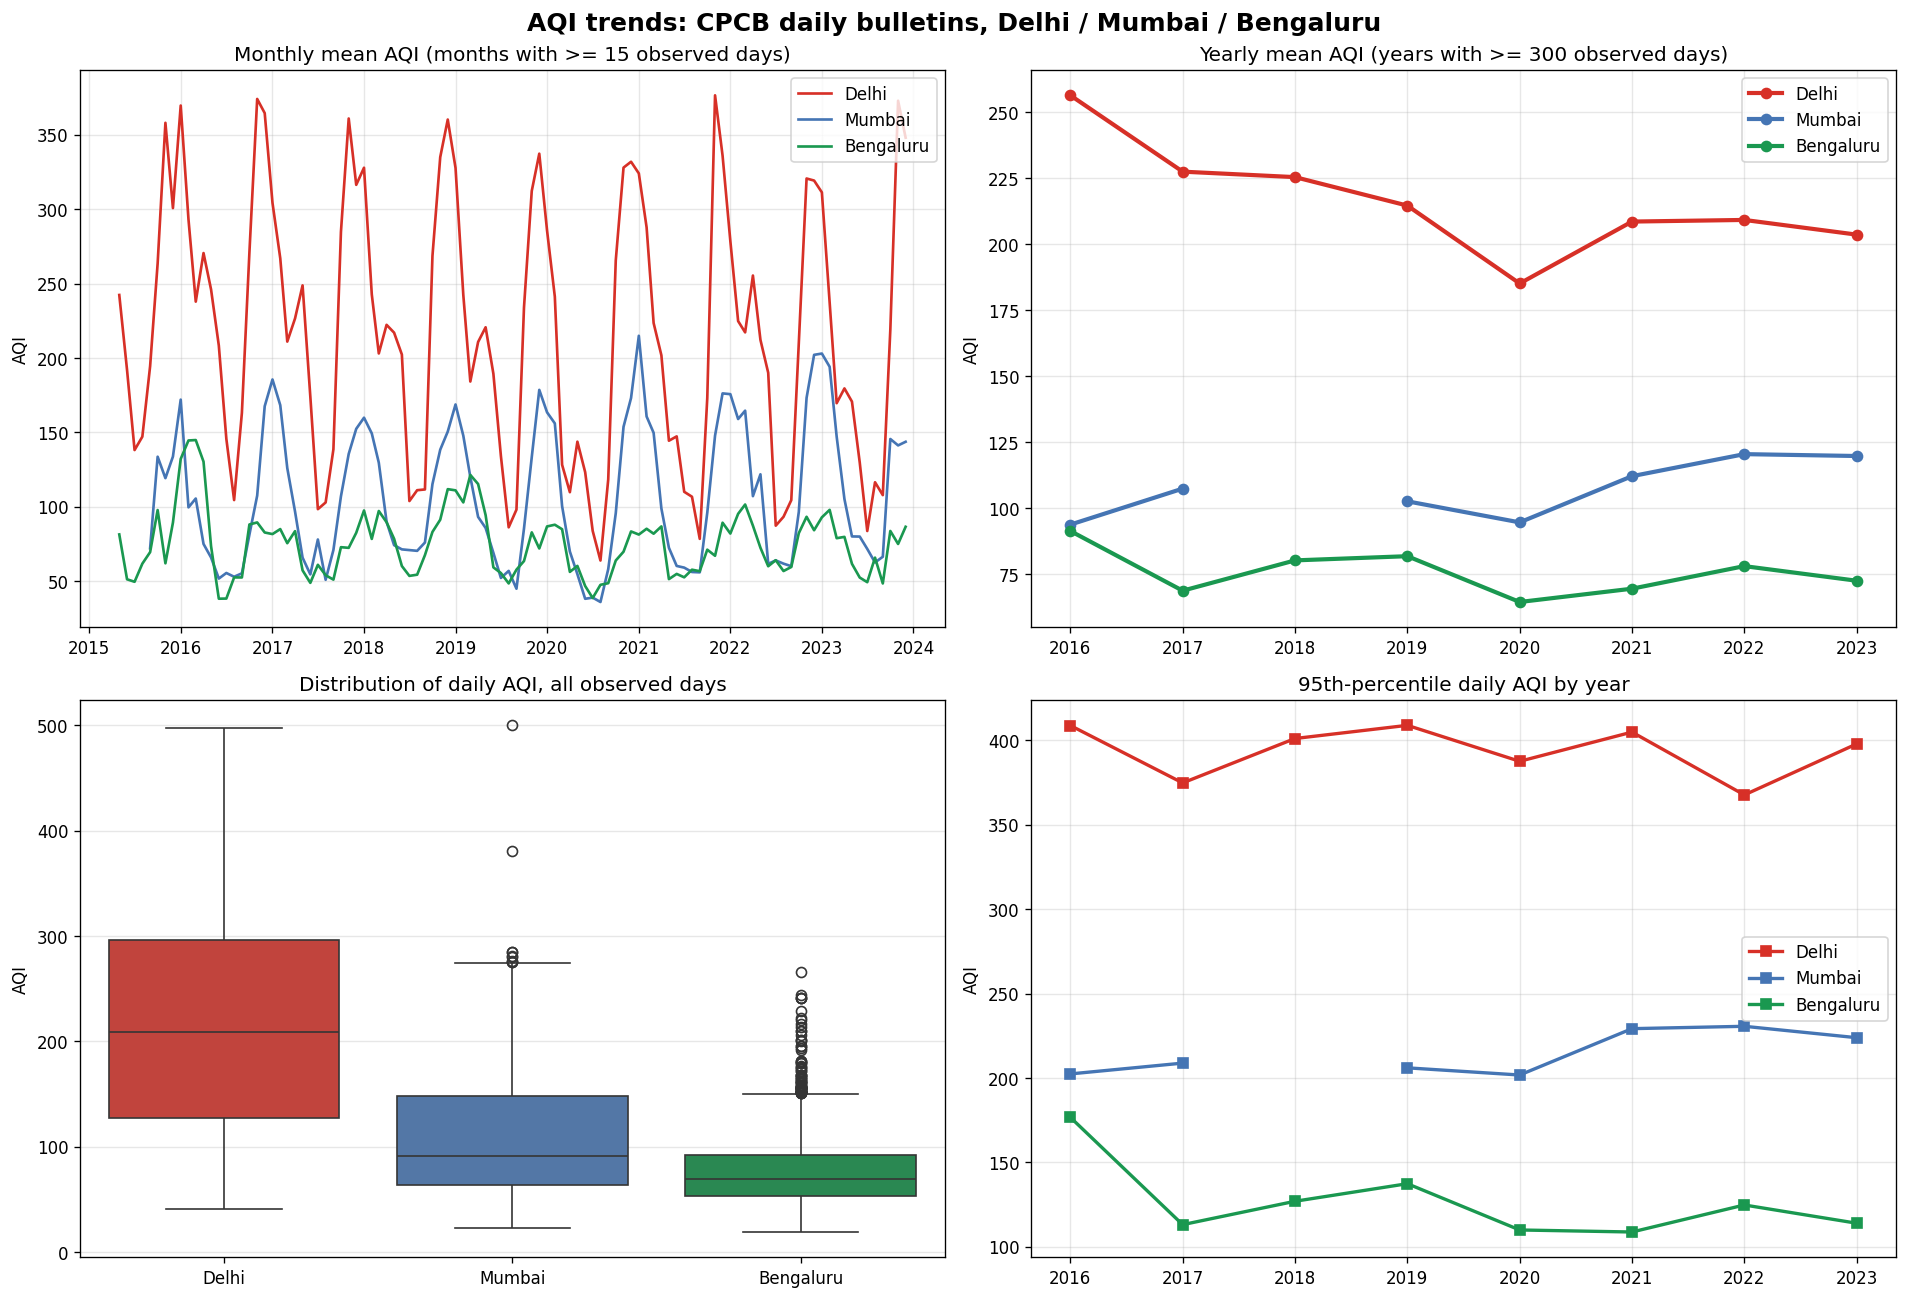

Yearly mean AQI (well-covered years only):
      Delhi  Mumbai  Bengaluru
year                          
2016  256.4    93.8       91.4
2017  227.5   107.5       68.8
2018  225.4     NaN       80.3
2019  214.6   102.7       81.9
2020  185.1    94.7       64.5
2021  208.6   112.2       69.6
2022  209.2   120.5       78.1
2023  203.6   119.8       72.6

Year-over-year change in yearly mean (consecutive well-covered years only):
      Delhi  Mumbai  Bengaluru
year                          
2016    NaN     NaN        NaN
2017  -28.9    13.6      -22.6
2018   -2.1     NaN       11.5
2019  -10.8     NaN        1.6
2020  -29.5    -8.0      -17.3
2021   23.4    17.5        5.0
2022    0.6     8.3        8.5
2023   -5.6    -0.7       -5.5


In [9]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 11))

monthly = aqi.assign(ym=aqi['date'].dt.to_period('M')).groupby(['city', 'ym'])['aqi'].agg(['mean', 'count']).reset_index()
monthly = monthly[monthly['count'] >= 15]
for c in CITIES:
    m = monthly[monthly['city'] == c]
    ax1.plot(m['ym'].dt.to_timestamp(), m['mean'], label=c, color=COLORS[c], lw=1.6)
ax1.set(title='Monthly mean AQI (months with >= 15 observed days)', ylabel='AQI')
ax1.legend()

yearly = pd.DataFrame({c: aqi[(aqi.city == c) & aqi.year.isin(complete_years[c])].groupby('year')['aqi'].mean() for c in CITIES})
for c in CITIES:
    ax2.plot(yearly.index, yearly[c], marker='o', lw=2.5, label=c, color=COLORS[c])
ax2.set(title=f'Yearly mean AQI (years with >= {MIN_DAYS_FULL_YEAR} observed days)', ylabel='AQI')
ax2.legend()

sns.boxplot(data=aqi, x='city', y='aqi', order=CITIES, hue='city', hue_order=CITIES, palette=COLORS, legend=False, ax=ax3)
ax3.set(title='Distribution of daily AQI, all observed days', xlabel='', ylabel='AQI')

p95 = pd.DataFrame({c: aqi[(aqi.city == c) & aqi.year.isin(complete_years[c])].groupby('year')['aqi'].quantile(0.95) for c in CITIES})
for c in CITIES:
    ax4.plot(p95.index, p95[c], marker='s', lw=2, label=c, color=COLORS[c])
ax4.set(title='95th-percentile daily AQI by year', ylabel='AQI')
ax4.legend()

fig.suptitle('AQI trends: CPCB daily bulletins, Delhi / Mumbai / Bengaluru', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(VISUALS / '01_aqi_trends.png', dpi=200, bbox_inches='tight')
plt.show()

print('Yearly mean AQI (well-covered years only):')
print(yearly.round(1).to_string())
print()
print('Year-over-year change in yearly mean (consecutive well-covered years only):')
print(yearly.diff().where(yearly.notna() & yearly.shift().notna()).round(1).to_string())

## 8. Seasonal Analysis (EMPIRICAL)

Seasons: Winter = Dec-Feb, Pre-monsoon = Mar-May, Monsoon = Jun-Sep, Post-monsoon = Oct-Nov.

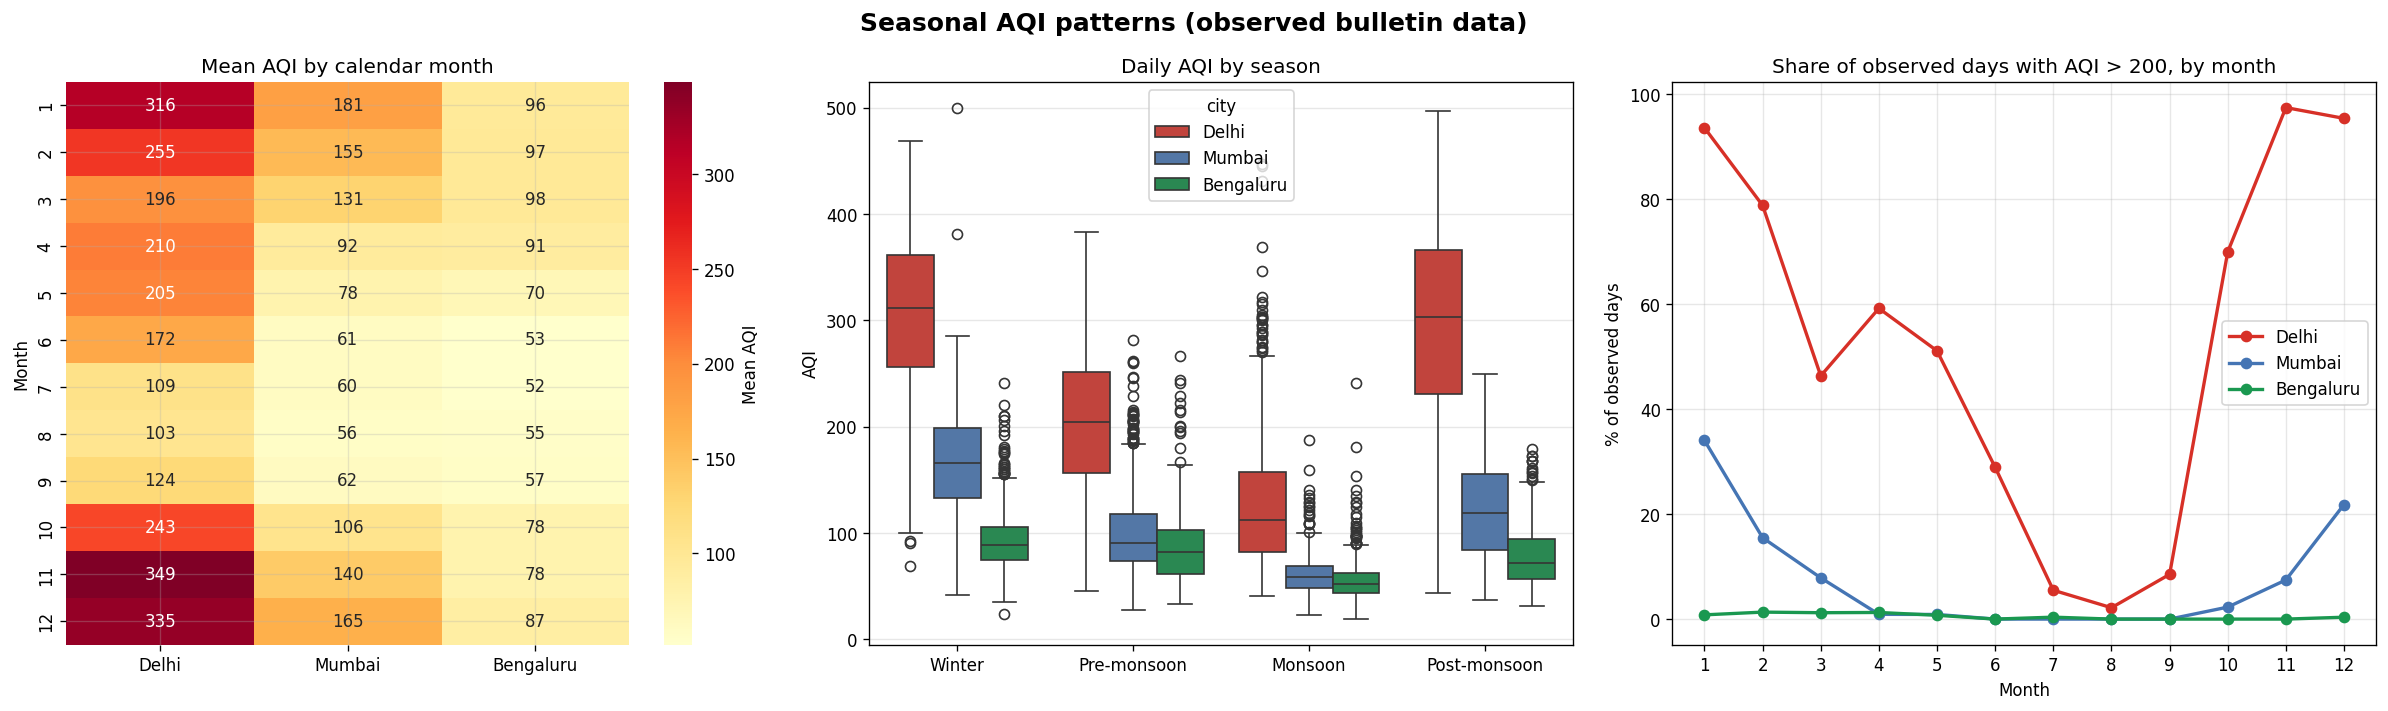

Mean AQI by season:
city          Delhi  Mumbai  Bengaluru
season                                
Winter        304.6   167.2       92.9
Pre-monsoon   203.6   101.2       85.8
Monsoon       126.6    59.9       54.2
Post-monsoon  295.1   122.5       78.3

Delhi: highest-mean month = 11 (349), lowest-mean month = 8 (103)
Mumbai: highest-mean month = 1 (181), lowest-mean month = 8 (56)
Bengaluru: highest-mean month = 3 (98), lowest-mean month = 7 (52)


In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

monthly_pivot = aqi.pivot_table(index='month', columns='city', values='aqi', aggfunc='mean').reindex(columns=CITIES)
sns.heatmap(monthly_pivot, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax1, cbar_kws={'label': 'Mean AQI'})
ax1.set(title='Mean AQI by calendar month', xlabel='', ylabel='Month')

sns.boxplot(data=aqi, x='season', y='aqi', hue='city', order=SEASON_ORDER, hue_order=CITIES, palette=COLORS, ax=ax2)
ax2.set(title='Daily AQI by season', xlabel='', ylabel='AQI')

poor = aqi.assign(poor=(aqi['aqi'] > 200)).pivot_table(index='month', columns='city', values='poor', aggfunc='mean').reindex(columns=CITIES) * 100
for c in CITIES:
    ax3.plot(poor.index, poor[c], marker='o', lw=2, label=c, color=COLORS[c])
ax3.set(title='Share of observed days with AQI > 200, by month', xlabel='Month', ylabel='% of observed days', xticks=range(1, 13))
ax3.legend()

fig.suptitle('Seasonal AQI patterns (observed bulletin data)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(VISUALS / '02_seasonal_patterns.png', dpi=200, bbox_inches='tight')
plt.show()

season_mean = aqi.pivot_table(index='season', columns='city', values='aqi', aggfunc='mean').reindex(index=SEASON_ORDER, columns=CITIES)
print('Mean AQI by season:')
print(season_mean.round(1).to_string())
print()
for c in CITIES:
    m = monthly_pivot[c]
    print(f'{c}: highest-mean month = {m.idxmax()} ({m.max():.0f}), lowest-mean month = {m.idxmin()} ({m.min():.0f})')

## 9. Extreme Event Analysis (EMPIRICAL)

Severe-pollution days are AQI > 300 (CPCB "Very Poor" or worse); hazardous days are AQI > 400 ("Severe"). Streaks require consecutive calendar dates, so missing dates end a streak (streak lengths are therefore lower bounds).

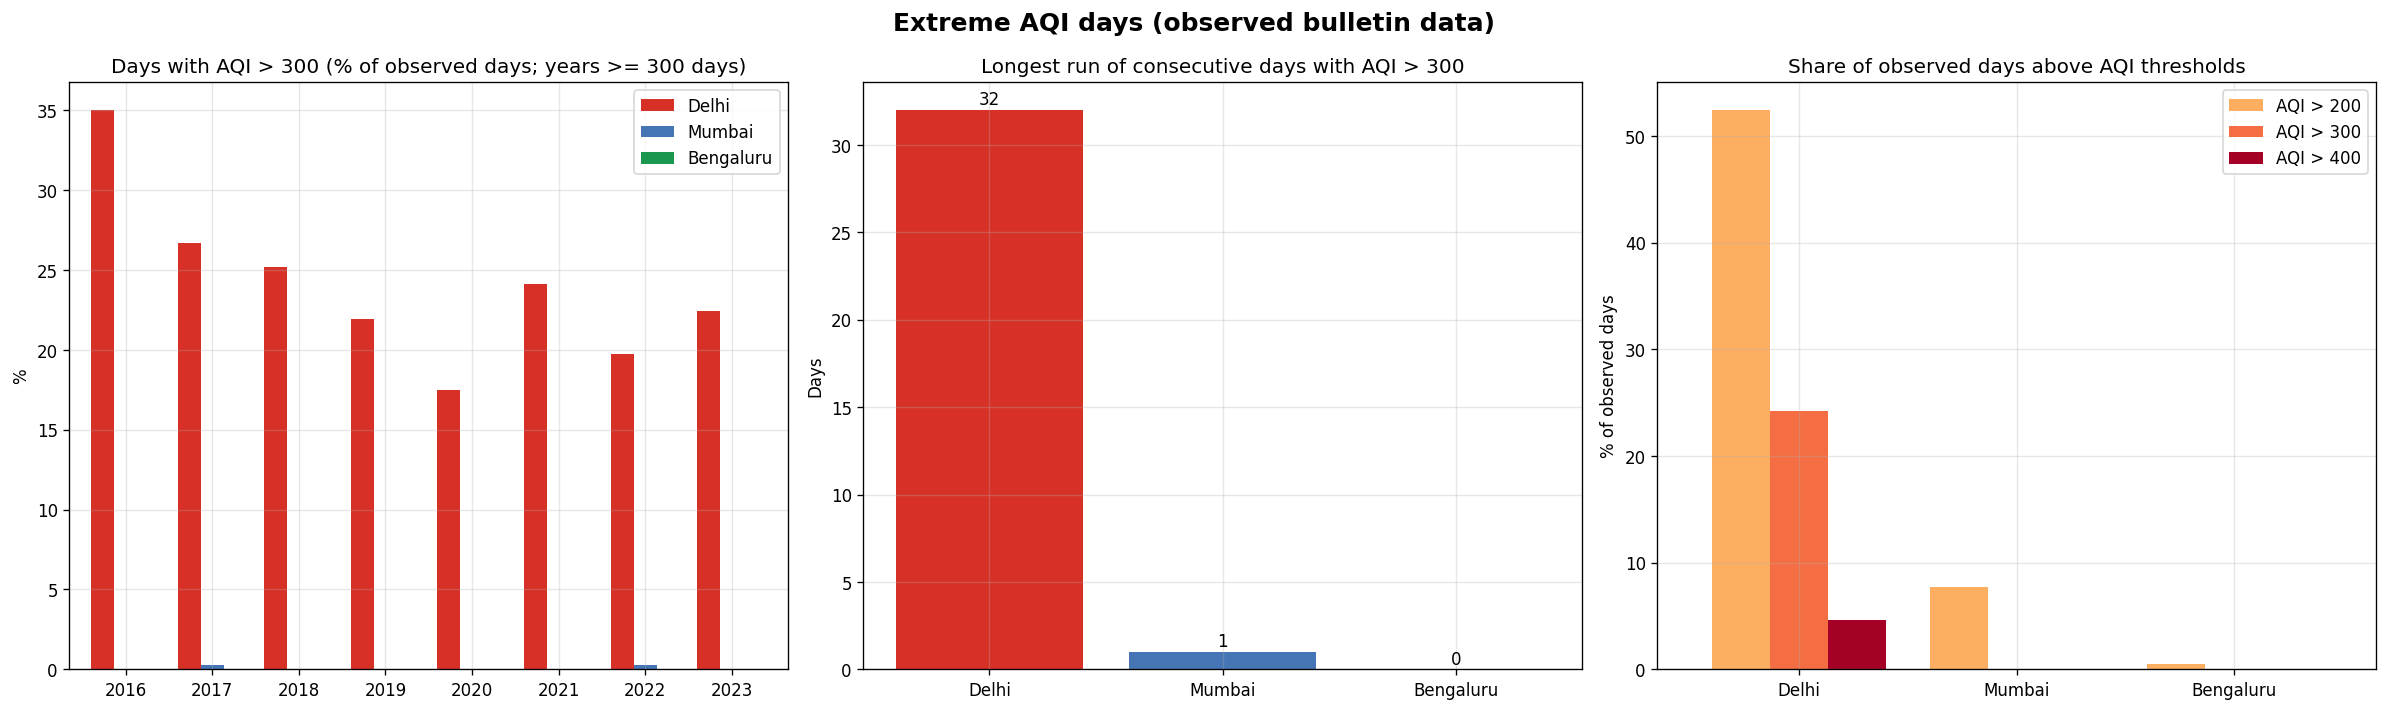

           observed_days  days_AQI>200  days_AQI>300  days_AQI>400  %_AQI>300  longest_>300_streak_days streak_start
city                                                                                                                
Delhi               3143          1648           761           146       24.2                        32   2017-10-17
Mumbai              2884           223             2             1        0.1                         1   2017-01-24
Bengaluru           3120            15             0             0        0.0                         0         None

Days with AQI > 300 per year (all years, counts depend on coverage):
city  Delhi  Mumbai  Bengaluru
year                          
2015     62       0          0
2016    124       0          0
2017     97       1          0
2018     92       0          0
2019     80       0          0
2020     64       0          0
2021     88       0          0
2022     72       1          0
2023     82       0          0


In [11]:
def longest_streak(g, threshold):
    g = g.sort_values('date')
    flag = g['aqi'] > threshold
    new_run = (~flag) | (g['date'].diff().dt.days.fillna(1) != 1)
    run_id = new_run.cumsum()
    runs = g[flag].groupby(run_id[flag])['date'].agg(['size', 'min'])
    if runs.empty:
        return 0, None
    best = runs.sort_values('size', ascending=False).iloc[0]
    return int(best['size']), best['min'].date()


aqi['severe'] = (aqi['aqi'] > 300).astype(int)
aqi['hazardous'] = (aqi['aqi'] > 400).astype(int)
aqi['poor_or_worse'] = (aqi['aqi'] > 200).astype(int)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

sev_year = pd.DataFrame({c: 100 * aqi[(aqi.city == c) & aqi.year.isin(complete_years[c])].groupby('year')['severe'].mean() for c in CITIES})
sev_year.plot(kind='bar', ax=ax1, color=[COLORS[c] for c in CITIES], width=0.8)
ax1.set(title=f'Days with AQI > 300 (% of observed days; years >= {MIN_DAYS_FULL_YEAR} days)', xlabel='', ylabel='%')
ax1.tick_params(axis='x', rotation=0)

streaks = {c: longest_streak(aqi[aqi.city == c], 300) for c in CITIES}
bars = ax2.bar(CITIES, [streaks[c][0] for c in CITIES], color=[COLORS[c] for c in CITIES])
ax2.set(title='Longest run of consecutive days with AQI > 300', ylabel='Days')
for b, c in zip(bars, CITIES):
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, str(streaks[c][0]), ha='center')

thr = pd.DataFrame({f'AQI > {t}': [100 * (aqi[aqi.city == c]['aqi'] > t).mean() for c in CITIES] for t in (200, 300, 400)}, index=CITIES)
thr.plot(kind='bar', ax=ax3, width=0.8, color=['#fdae61', '#f46d43', '#a50026'])
ax3.set(title='Share of observed days above AQI thresholds', xlabel='', ylabel='% of observed days')
ax3.tick_params(axis='x', rotation=0)

fig.suptitle('Extreme AQI days (observed bulletin data)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(VISUALS / '03_extreme_events.png', dpi=200, bbox_inches='tight')
plt.show()

ext = pd.DataFrame({
    'observed_days': aqi.groupby('city').size(),
    'days_AQI>200': aqi.groupby('city')['poor_or_worse'].sum(),
    'days_AQI>300': aqi.groupby('city')['severe'].sum(),
    'days_AQI>400': aqi.groupby('city')['hazardous'].sum(),
}).reindex(CITIES)
ext['%_AQI>300'] = (100 * ext['days_AQI>300'] / ext['observed_days']).round(1)
ext['longest_>300_streak_days'] = [streaks[c][0] for c in CITIES]
ext['streak_start'] = [streaks[c][1] for c in CITIES]
print(ext.to_string())
print()
print('Days with AQI > 300 per year (all years, counts depend on coverage):')
print(aqi.pivot_table(index='year', columns='city', values='severe', aggfunc='sum').reindex(columns=CITIES).fillna(0).astype(int).to_string())

## 10. City Comparison (EMPIRICAL)

In [12]:
comp = pd.DataFrame({
    'mean_AQI': aqi.groupby('city')['aqi'].mean(),
    'median_AQI': aqi.groupby('city')['aqi'].median(),
    'p95_AQI': aqi.groupby('city')['aqi'].quantile(0.95),
    'max_AQI': aqi.groupby('city')['aqi'].max(),
    'std_AQI': aqi.groupby('city')['aqi'].std(),
    'winter_mean_AQI': aqi[aqi.season == 'Winter'].groupby('city')['aqi'].mean(),
    'monsoon_mean_AQI': aqi[aqi.season == 'Monsoon'].groupby('city')['aqi'].mean(),
    '%_days_AQI>200': 100 * aqi.groupby('city')['poor_or_worse'].mean(),
    '%_days_AQI>300': 100 * aqi.groupby('city')['severe'].mean(),
}).reindex(CITIES).round(1)
print(comp.T.to_string())

prom = (aqi.dropna(subset=['prominent_pollutant']).groupby('city')['prominent_pollutant'].value_counts(normalize=True)
        .mul(100).groupby(level=0).head(3).round(1))
print()
print('Most frequent "prominent pollutant" entries in the bulletins (% of days with an entry):')
print(prom.to_string())

city              Delhi  Mumbai  Bengaluru
mean_AQI          217.1   108.2       75.4
median_AQI        209.0    91.0       69.0
p95_AQI           399.0   214.0      132.0
max_AQI           497.0   500.0      266.0
std_AQI           104.0    56.2       30.5
winter_mean_AQI   304.6   167.2       92.9
monsoon_mean_AQI  126.6    59.9       54.2
%_days_AQI>200     52.4     7.7        0.5
%_days_AQI>300     24.2     0.1        0.0

Most frequent "prominent pollutant" entries in the bulletins (% of days with an entry):
city       prominent_pollutant
Bengaluru  PM10, PM2.5            17.5
           CO, PM10, PM2.5        11.8
           O3, PM2.5               8.2
Delhi      PM10, PM2.5            41.7
           PM2.5                  21.0
           PM10                    6.8
Mumbai     PM10                   29.4
           PM10, PM2.5            13.7
           PM2.5                  13.0


## 11. Weather-AQI Relationship (EMPIRICAL, Delhi and Bengaluru only)

Uses only matched IMD-sourced daily temperature and rainfall (Section 4); no simulated values. Mumbai is excluded
(no weather file).

Raw correlations between AQI and weather are dominated by the shared annual cycle, so the table also reports a
**month-adjusted** Spearman correlation (each variable minus its mean for the same city and calendar month). These
are associations, not causal effects; wind, humidity and emissions are not in the data. Rainfall units are not stated
in the file; rank correlations do not depend on units.

In [13]:
WCITIES = ['Delhi', 'Bengaluru']
rows = []
for c in WCITIES:
    g = aqi[aqi.city == c]
    for v in ['temp_max', 'temp_min', 'rain_mm']:
        h = g[['aqi', v, 'month']].dropna()
        adj_a = h['aqi'] - h.groupby('month')['aqi'].transform('mean')
        adj_v = h[v] - h.groupby('month')[v].transform('mean')
        rows.append({'city': c, 'variable': v, 'n_days': len(h),
                     'spearman_raw': h['aqi'].corr(h[v], method='spearman'),
                     'spearman_month_adjusted': adj_a.corr(adj_v, method='spearman')})
wcorr = pd.DataFrame(rows).round(2)
print(wcorr.to_string(index=False))

# Rain / dry days outside the monsoon season (Oct-May), to limit the seasonal confound
dry_rain = aqi[aqi.city.isin(WCITIES) & aqi.rain_mm.notna() & (aqi.season != 'Monsoon')].copy()
dry_rain['day_type'] = np.where(dry_rain['rain_mm'] >= 1, 'Rain (>= 1)', 'Dry (< 1)')
print()
print('Mean AQI on dry vs rainy days, non-monsoon months (rain threshold 1 in file units):')
print(dry_rain.groupby(['city', 'day_type'])['aqi'].agg(['count', 'mean']).round(1).to_string())

     city variable  n_days  spearman_raw  spearman_month_adjusted
    Delhi temp_max    3113         -0.37                     0.34
    Delhi temp_min    3112         -0.63                     0.10
    Delhi  rain_mm    3113         -0.45                    -0.14
Bengaluru temp_max    3117          0.25                     0.28
Bengaluru temp_min    3115         -0.29                    -0.10
Bengaluru  rain_mm    3117         -0.42                    -0.17

Mean AQI on dry vs rainy days, non-monsoon months (rain threshold 1 in file units):
                       count   mean
city      day_type                 
Bengaluru Dry (< 1)     1722   90.2
          Rain (>= 1)    330   66.5
Delhi     Dry (< 1)     1912  269.8
          Rain (>= 1)    118  161.0


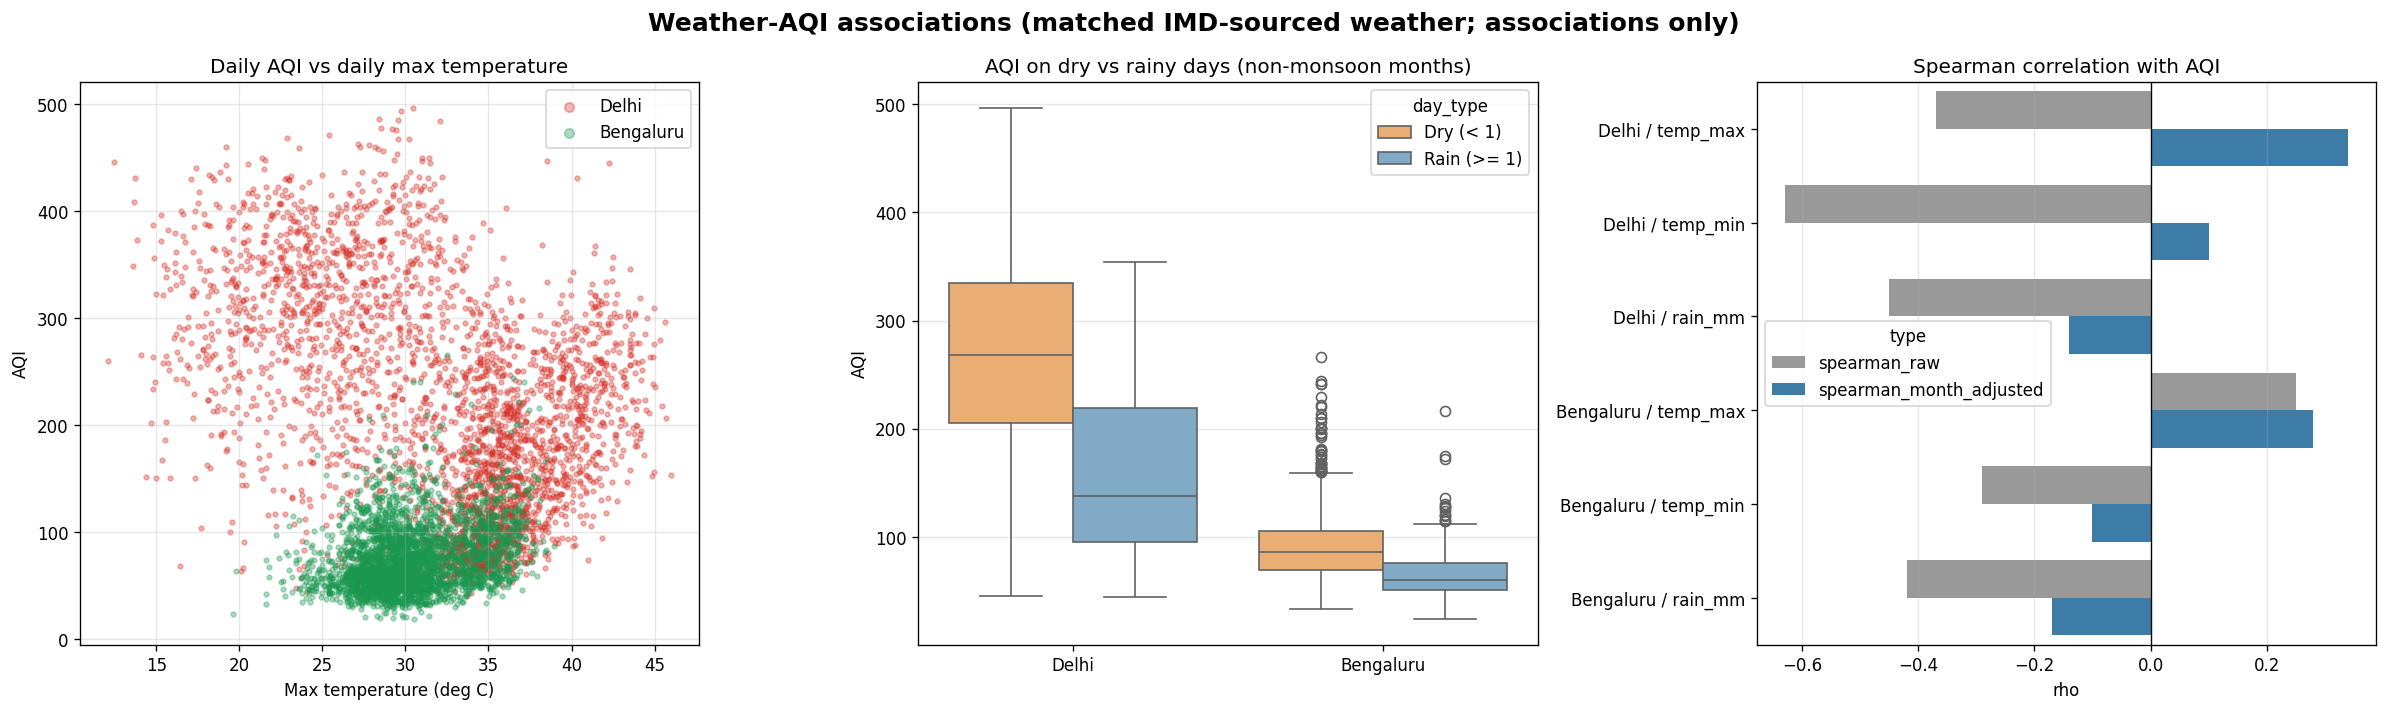

In [14]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

for c in WCITIES:
    g = aqi[aqi.city == c].dropna(subset=['temp_max'])
    ax1.scatter(g['temp_max'], g['aqi'], s=8, alpha=0.35, color=COLORS[c], label=c)
ax1.set(title='Daily AQI vs daily max temperature', xlabel='Max temperature (deg C)', ylabel='AQI')
ax1.legend(markerscale=2)

sns.boxplot(data=dry_rain, x='city', y='aqi', hue='day_type', order=WCITIES, hue_order=['Dry (< 1)', 'Rain (>= 1)'],
            palette=['#fdae61', '#74add1'], ax=ax2)
ax2.set(title='AQI on dry vs rainy days (non-monsoon months)', xlabel='', ylabel='AQI')

plot_c = wcorr.melt(id_vars=['city', 'variable', 'n_days'], value_vars=['spearman_raw', 'spearman_month_adjusted'],
                    var_name='type', value_name='rho')
plot_c['label'] = plot_c['city'] + ' / ' + plot_c['variable']
sns.barplot(data=plot_c, y='label', x='rho', hue='type', ax=ax3, palette=['#999999', '#2c7fb8'])
ax3.axvline(0, color='black', lw=0.8)
ax3.set(title='Spearman correlation with AQI', xlabel='rho', ylabel='')

fig.suptitle('Weather-AQI associations (matched IMD-sourced weather; associations only)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(VISUALS / '06_weather_aqi_relationship.png', dpi=200, bbox_inches='tight')
plt.show()

## 12. Risk Scoring (HEURISTIC)

### Heuristic Risk Score

Each observed day gets points by CPCB category (Good 0, Satisfactory 1, Moderate 2, Poor 3, Very Poor 4, Severe 5).
The city score is the mean points scaled to 0-100 (100 would mean every day is "Severe"). The equal one-point steps are
a **project-defined choice, not an official or validated index**. It uses observed AQI only; scores are computed
over observed days, so cities with different coverage are not weighted by missing days.

           heuristic_risk_score  mean_AQI  median_AQI  p95_AQI
city                                                          
Delhi                      52.9     217.1       209.0    399.0
Mumbai                     28.1     108.2        91.0    214.0
Bengaluru                  19.6      75.4        69.0    132.0


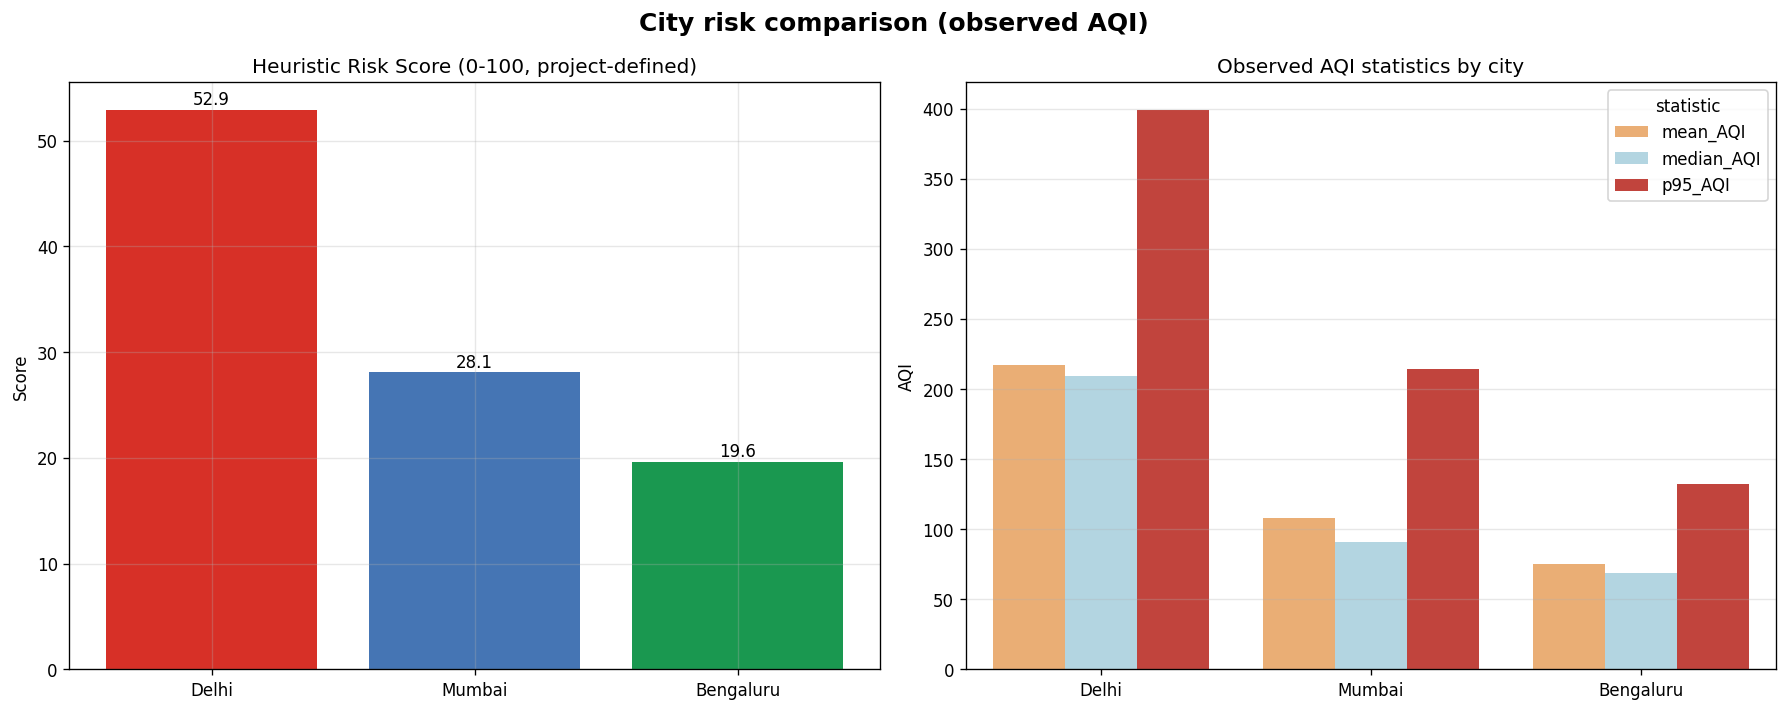

In [15]:
POINTS = {cat: i for i, cat in enumerate(CAT_ORDER)}
aqi['risk_points'] = aqi['aqi_category'].map(POINTS)
risk = pd.DataFrame({
    'heuristic_risk_score': (100 * aqi.groupby('city')['risk_points'].mean() / max(POINTS.values())),
    'mean_AQI': aqi.groupby('city')['aqi'].mean(),
    'median_AQI': aqi.groupby('city')['aqi'].median(),
    'p95_AQI': aqi.groupby('city')['aqi'].quantile(0.95),
}).reindex(CITIES).round(1)
print(risk.to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
bars = ax1.bar(CITIES, risk['heuristic_risk_score'], color=[COLORS[c] for c in CITIES])
ax1.set(title='Heuristic Risk Score (0-100, project-defined)', ylabel='Score')
for b, v in zip(bars, risk['heuristic_risk_score']):
    ax1.text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:.1f}', ha='center')

stats = risk[['mean_AQI', 'median_AQI', 'p95_AQI']].reset_index().melt(id_vars='city', var_name='statistic', value_name='AQI')
sns.barplot(data=stats, x='city', y='AQI', hue='statistic', order=CITIES, palette=['#fdae61', '#abd9e9', '#d73027'], ax=ax2)
ax2.set(title='Observed AQI statistics by city', xlabel='')

fig.suptitle('City risk comparison (observed AQI)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(VISUALS / '04_city_risk_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

### Risk segmentation by AQI category (EMPIRICAL)

Share of observed days in each CPCB category, and share of days with AQI > 200 by city and season.

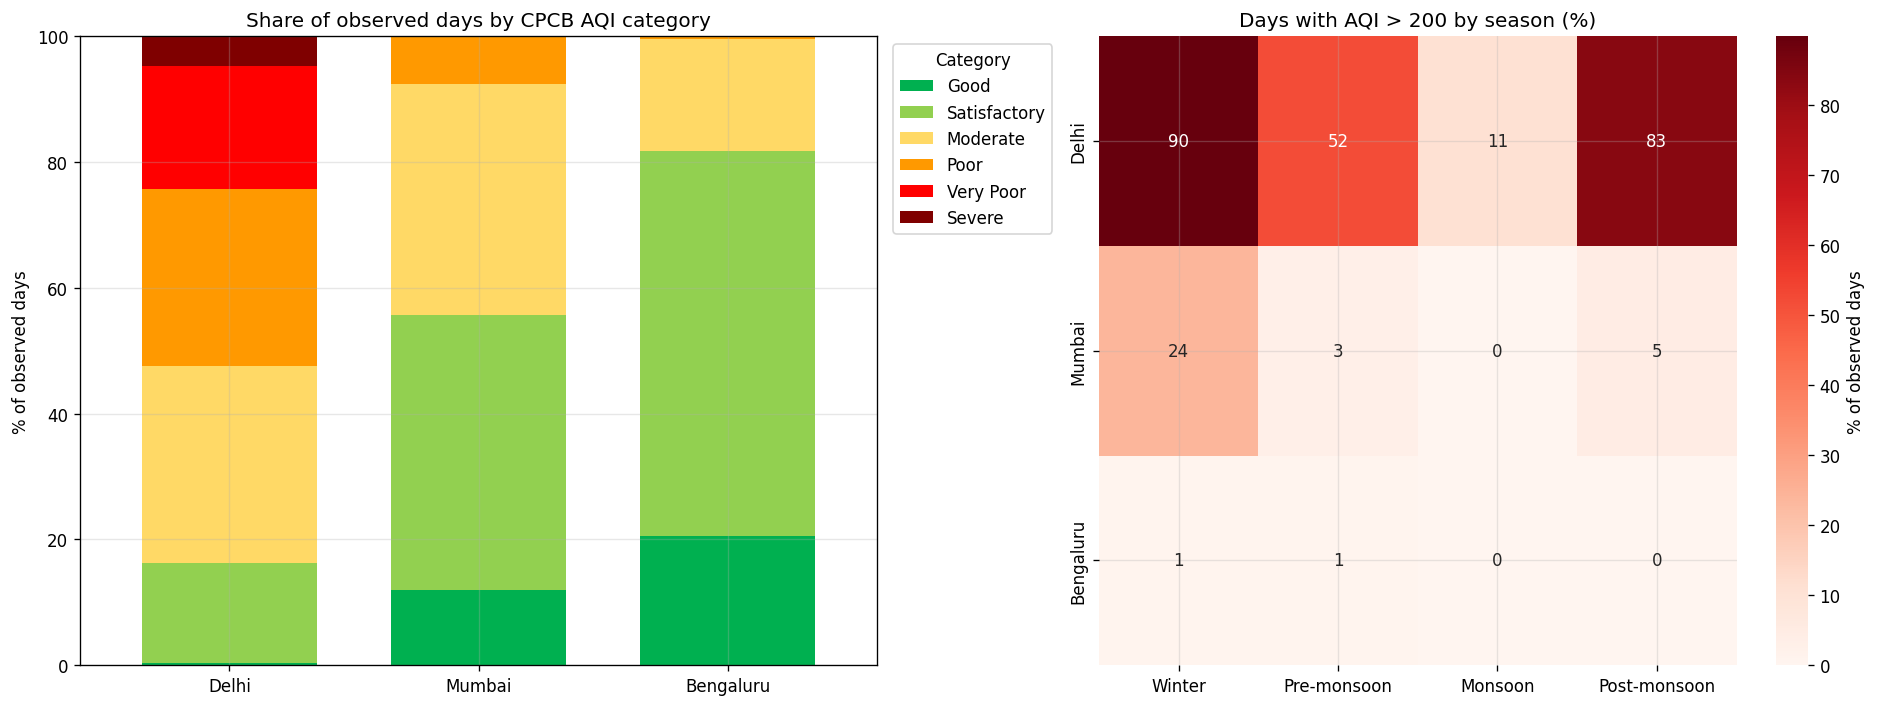

season     Winter  Pre-monsoon  Monsoon  Post-monsoon
city                                                 
Delhi        89.8         52.1     11.1          83.5
Mumbai       24.0          3.3      0.0           4.8
Bengaluru     0.8          1.1      0.1           0.0


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

cat_share.plot(kind='bar', stacked=True, ax=ax1, color=['#00b050', '#92d050', '#ffd966', '#ff9900', '#ff0000', '#7f0000'], width=0.7)
ax1.set(title='Share of observed days by CPCB AQI category', xlabel='', ylabel='% of observed days')
ax1.tick_params(axis='x', rotation=0)
ax1.legend(title='Category', bbox_to_anchor=(1.01, 1), loc='upper left')

season_poor = aqi.pivot_table(index='city', columns='season', values='poor_or_worse', aggfunc='mean').reindex(index=CITIES, columns=SEASON_ORDER) * 100
sns.heatmap(season_poor, annot=True, fmt='.0f', cmap='Reds', ax=ax2, cbar_kws={'label': '% of observed days'})
ax2.set(title='Days with AQI > 200 by season (%)', xlabel='', ylabel='')

plt.tight_layout()
plt.savefig(VISUALS / '08_risk_segmentation.png', dpi=200, bbox_inches='tight')
plt.show()
print(season_poor.round(1).to_string())

## 13. Linear Trend Projection (PROJECTION)

For each city a straight line is fitted (`np.polyfit`, degree 1) to the **yearly mean AQI of well-covered years**
(>= 300 observed days) and extended to 2024-2026. This is a **linear trend projection**, not a validated forecasting
model: it uses 7-8 points per city, ignores seasonality within a year, treats 2020 (COVID-19 lockdown year) like any
other year, and is not tested on held-out data. Changes in the number of reporting stations (Section 3) are also not accounted for. The shaded band is +/- one residual standard error of the fit and is
not a formal prediction interval. The bulletin file ends in 2023, so the projection cannot be checked against this data.

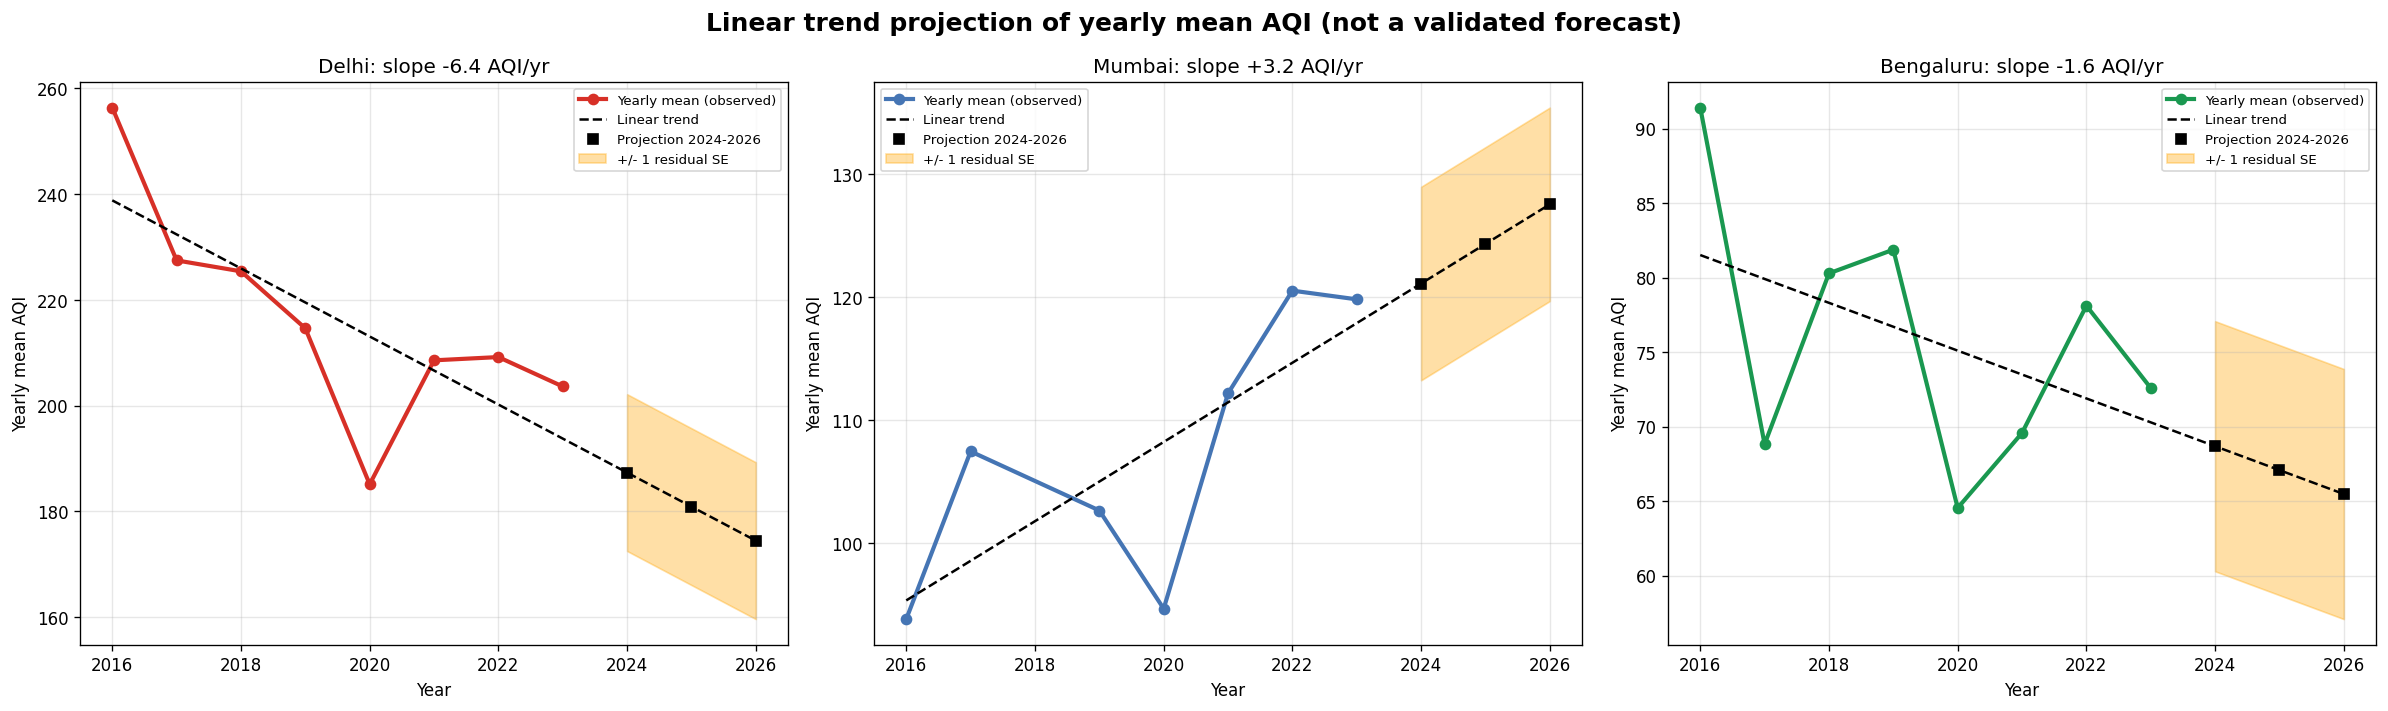

                  years_used  slope_AQI_per_year  residual_SE  proj_2024  proj_2025  proj_2026
city                                                                                          
Delhi      2016-2023 (8 yrs)                -6.4         14.8      187.3      180.9      174.5
Mumbai     2016-2023 (7 yrs)                 3.2          7.9      121.1      124.3      127.5
Bengaluru  2016-2023 (8 yrs)                -1.6          8.4       68.7       67.1       65.5


In [17]:
proj_years = np.array([2024, 2025, 2026])
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)
proj_rows = []
for ax, c in zip(axes, CITIES):
    y = yearly[c].dropna()
    slope, intercept = np.polyfit(y.index.values, y.values, 1)
    fitted = slope * y.index.values + intercept
    se = np.sqrt(((y.values - fitted) ** 2).sum() / (len(y) - 2))
    proj = slope * proj_years + intercept
    proj_rows.append({'city': c, 'years_used': f'{y.index.min()}-{y.index.max()} ({len(y)} yrs)', 'slope_AQI_per_year': slope,
                      'residual_SE': se, **{f'proj_{yr}': p for yr, p in zip(proj_years, proj)}})
    ax.plot(y.index, y.values, 'o-', lw=2.5, color=COLORS[c], label='Yearly mean (observed)')
    ax.plot(np.r_[y.index.values, proj_years], slope * np.r_[y.index.values, proj_years] + intercept, 'k--', lw=1.5, label='Linear trend')
    ax.plot(proj_years, proj, 's', color='black', label='Projection 2024-2026')
    ax.fill_between(proj_years, proj - se, proj + se, color='orange', alpha=0.35, label='+/- 1 residual SE')
    ax.set(title=f'{c}: slope {slope:+.1f} AQI/yr', xlabel='Year', ylabel='Yearly mean AQI')
    ax.legend(fontsize=8)
fig.suptitle('Linear trend projection of yearly mean AQI (not a validated forecast)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(VISUALS / '05_trend_projection.png', dpi=200, bbox_inches='tight')
plt.show()

proj_df = pd.DataFrame(proj_rows).set_index('city').round(1)
print(proj_df.to_string())

## 14. Illustrative Policy Scenario Analysis (SCENARIO)

> **These are assumptions, not findings.** The scenarios below take the *observed* daily AQI and scale every day by
> a hypothetical uniform reduction (10%, 20%, 30%). The reductions are arbitrary illustrative levels, not estimates
> of any real policy's effect. AQI is set by the worst pollutant sub-index and does not scale linearly with emissions,
> so this only shows how threshold exceedances would change *if* such a reduction occurred. No policy is ranked.
> (Earlier versions of this project also contained a cost/ROI table and a per-person health-cost model; both were
> removed because every input was an unsourced assumption and the outputs only restated those inputs.)

     city  assumed_reduction_%  mean_AQI  %_days_>200  %_days_>300
    Delhi                    0     217.1         52.4         24.2
    Delhi                   10     195.4         45.9         16.2
    Delhi                   20     173.7         38.2          8.1
    Delhi                   30     152.0         27.8          1.9
   Mumbai                    0     108.2          7.7          0.1
   Mumbai                   10      97.3          3.6          0.1
   Mumbai                   20      86.5          1.1          0.1
   Mumbai                   30      75.7          0.1          0.0
Bengaluru                    0      75.4          0.5          0.0
Bengaluru                   10      67.9          0.2          0.0
Bengaluru                   20      60.3          0.0          0.0
Bengaluru                   30      52.8          0.0          0.0


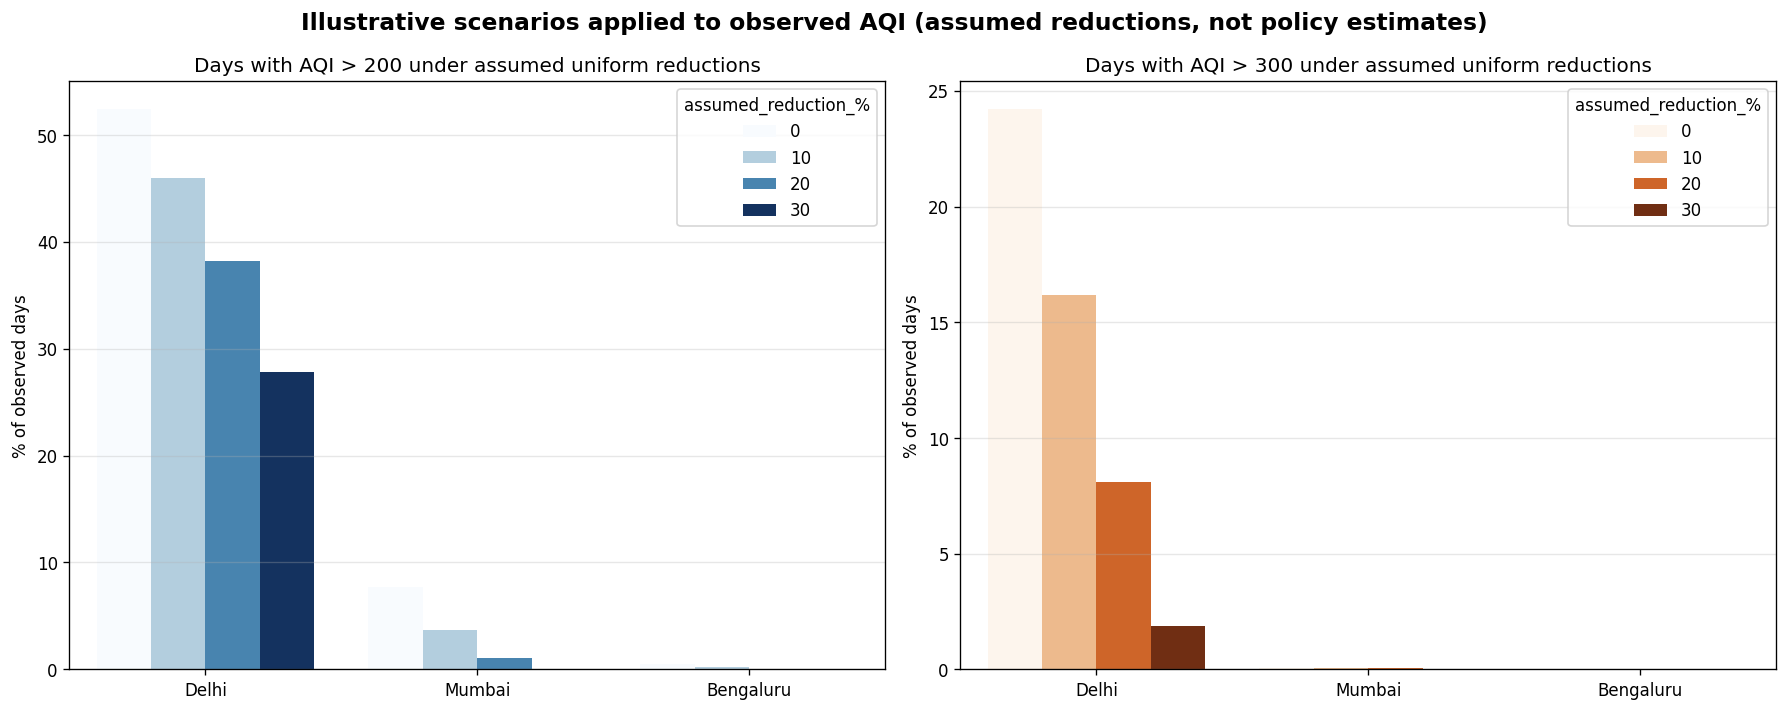

In [18]:
levels = [0, 10, 20, 30]
scen = []
for c in CITIES:
    s = aqi.loc[aqi.city == c, 'aqi']
    for r in levels:
        adj = s * (1 - r / 100)
        scen.append({'city': c, 'assumed_reduction_%': r, 'mean_AQI': adj.mean(),
                     '%_days_>200': 100 * (adj > 200).mean(), '%_days_>300': 100 * (adj > 300).mean()})
scen = pd.DataFrame(scen)
print(scen.round(1).to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=scen, x='city', y='%_days_>200', hue='assumed_reduction_%', order=CITIES, palette='Blues', ax=ax1)
ax1.set(title='Days with AQI > 200 under assumed uniform reductions', xlabel='', ylabel='% of observed days')
sns.barplot(data=scen, x='city', y='%_days_>300', hue='assumed_reduction_%', order=CITIES, palette='Oranges', ax=ax2)
ax2.set(title='Days with AQI > 300 under assumed uniform reductions', xlabel='', ylabel='% of observed days')
fig.suptitle('Illustrative scenarios applied to observed AQI (assumed reductions, not policy estimates)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(VISUALS / '07_policy_scenarios.png', dpi=200, bbox_inches='tight')
plt.show()

## 15. Rule-Based AQI Alert Demonstration

A small demonstration of threshold rules, applied to the observed historical days. The levels are project-defined and
follow the CPCB category bounds; they are **not** official GRAP stages and this is not a real-time monitoring system.

| Level | Rule |
|---|---|
| 0 | AQI <= 200 |
| 1 | AQI 201-300 |
| 2 | AQI 301-400 |
| 3 | AQI > 400 |

In [19]:
def alert_level(value):
    if value > 400:
        return 3
    if value > 300:
        return 2
    if value > 200:
        return 1
    return 0


aqi['alert_level'] = aqi['aqi'].map(alert_level)
alert_counts = aqi.groupby(['city', 'alert_level']).size().unstack(fill_value=0).reindex(index=CITIES, columns=[0, 1, 2, 3], fill_value=0)
print('Observed days by alert level (historical replay):')
print(alert_counts.to_string())
print()
print('Replay of the last 5 observed days per city:')
for c in CITIES:
    last = aqi[aqi.city == c].tail(5)
    print(c + ':', '; '.join(f"{d.date()} AQI {a} -> level {l}" for d, a, l in zip(last['date'], last['aqi'], last['alert_level'])))

Observed days by alert level (historical replay):
alert_level     0    1    2    3
city                            
Delhi        1495  887  615  146
Mumbai       2661  221    1    1
Bengaluru    3105   15    0    0

Replay of the last 5 observed days per city:
Delhi: 2023-12-27 AQI 380 -> level 2; 2023-12-28 AQI 358 -> level 2; 2023-12-29 AQI 382 -> level 2; 2023-12-30 AQI 400 -> level 2; 2023-12-31 AQI 382 -> level 2
Mumbai: 2023-12-27 AQI 174 -> level 0; 2023-12-28 AQI 194 -> level 0; 2023-12-29 AQI 181 -> level 0; 2023-12-30 AQI 161 -> level 0; 2023-12-31 AQI 143 -> level 0
Bengaluru: 2023-12-27 AQI 78 -> level 0; 2023-12-28 AQI 80 -> level 0; 2023-12-29 AQI 72 -> level 0; 2023-12-30 AQI 67 -> level 0; 2023-12-31 AQI 73 -> level 0


## 16. Final Results

In [20]:
print('DATA (EMPIRICAL)')
print(f'  Source: CPCB daily AQI bulletins via Zenodo 10.5281/zenodo.11146316 (md5 verified: {md5 == ZENODO_MD5})')
print(f'  Observations: {len(aqi):,} city-days, {aqi.date.min().date()} to {aqi.date.max().date()}')
print(quality[['observations', 'missing_dates_in_span', 'coverage_%']].to_string())
print()
print('EMPIRICAL RESULTS')
print(comp.loc[CITIES, ['mean_AQI', 'median_AQI', 'p95_AQI', '%_days_AQI>200', '%_days_AQI>300']].to_string())
print()
print('PROJECTION / HEURISTIC (not validated)')
print(proj_df[['slope_AQI_per_year', 'proj_2024', 'proj_2025', 'proj_2026']].to_string())
print(risk[['heuristic_risk_score']].to_string())
print()
print('SCENARIO (assumptions): see Section 14; alert levels are a rule-based demonstration (Section 15).')

DATA (EMPIRICAL)
  Source: CPCB daily AQI bulletins via Zenodo 10.5281/zenodo.11146316 (md5 verified: True)
  Observations: 9,147 city-days, 2015-05-01 to 2023-12-31
           observations  missing_dates_in_span  coverage_%
city                                                      
Delhi              3143                     24        99.2
Mumbai             2884                    172        94.4
Bengaluru          3120                     46        98.5

EMPIRICAL RESULTS
           mean_AQI  median_AQI  p95_AQI  %_days_AQI>200  %_days_AQI>300
city                                                                    
Delhi         217.1       209.0    399.0            52.4            24.2
Mumbai        108.2        91.0    214.0             7.7             0.1
Bengaluru      75.4        69.0    132.0             0.5             0.0

PROJECTION / HEURISTIC (not validated)
           slope_AQI_per_year  proj_2024  proj_2025  proj_2026
city                                                